Importing the libraries

In [207]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re
import seaborn as sns
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.model_selection import train_test_split
from sklearn.metrics import*

## Problem Statement:

### In this data, we have one independent variable, i.e temperature, and one dependent variable i.e revenue. You have to build a decision tree regressor to study the relationship between the two variables, and then predict the revenue based on the temperature on a particular day

## Solution:

Import the dataset : https://raw.githubusercontent.com/mk-gurucharan/Regression/master/IceCreamData.csv

In [208]:
df=pd.read_csv('https://raw.githubusercontent.com/mk-gurucharan/Regression/master/IceCreamData.csv')

In [209]:
df.head()

,Temperature,Revenue
0,24.566884,534.799028
1,26.005191,625.190122
2,27.790554,660.632289
3,20.595335,487.706960
4,11.503498,316.240194


In [210]:
df.tail()

,Temperature,Revenue
495,22.274899,524.746364
496,32.893092,755.818399
497,12.588157,306.090719
498,22.362402,566.217304
499,28.957736,655.660388


EDA -> Exploratory Data Analysis

In [211]:
df.describe()

,Temperature,Revenue
count,500.000000,500.000000
mean,22.232225,521.570777
std,8.096388,175.404751
min,0.000000,10.000000
25%,17.122258,405.558681
50%,22.392791,529.368565
75%,27.740674,642.257922
max,45.000000,1000.000000


In [212]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Temperature  500 non-null    float64
 1   Revenue      500 non-null    float64
dtypes: float64(2)
memory usage: 7.9 KB


In [213]:
df.isnull().sum()

Temperature    0
Revenue        0
dtype: int64

Text(0.5, 1.0, 'Temperature v/s Revenue')

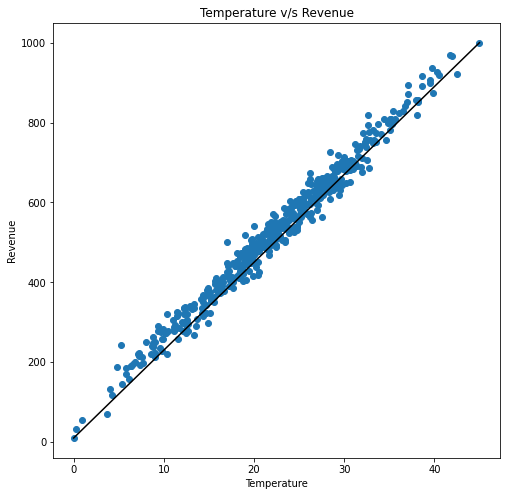

In [214]:
plt.figure(figsize=(8,8))
plt.scatter(df.Temperature,df.Revenue)
plt.plot([df.Temperature.min(),df.Temperature.max()],[df.Revenue.min(),df.Revenue.max()],color='black')
plt.xlabel('Temperature')
plt.ylabel('Revenue')
plt.title('Temperature v/s Revenue')

In [215]:
df.corr()

,Temperature,Revenue
Temperature,1.000000,0.989802
Revenue,0.989802,1.000000


<Axes: >

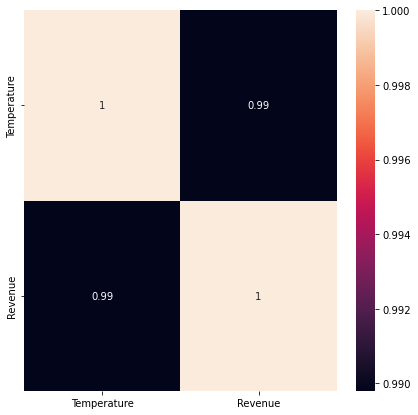

In [216]:
plt.figure(figsize=(7,7))
sns.heatmap(df.corr(),annot=True)

<Axes: ylabel='Revenue'>

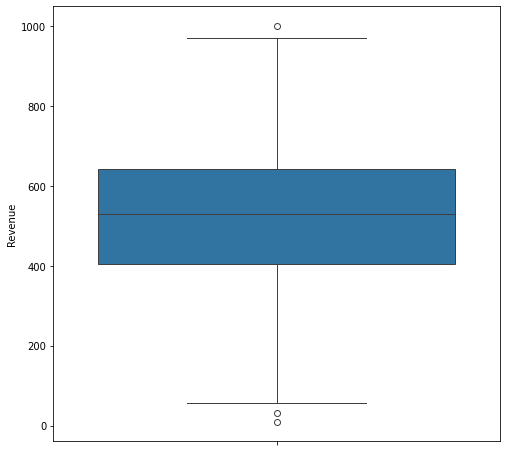

In [217]:
plt.figure(figsize=(8,8))
sns.boxplot(df.Revenue)

<Axes: ylabel='Temperature'>

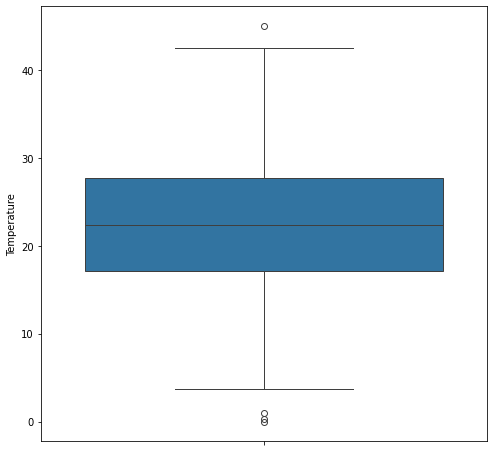

In [218]:
plt.figure(figsize=(8,8))
sns.boxplot(df.Temperature)

### Machine Learning

In [219]:
X=np.array(df.Temperature)
Y=np.array(df.Revenue).reshape(-1,1)

Splitting the data

In [220]:
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.2,random_state=25)

In [221]:
X_train=X_train.reshape(-1,1)
X_test=X_test.reshape(-1,1)
Y_train=Y_train.reshape(-1,1)
Y_test=Y_test.reshape(-1,1)

Choosing the model

In [222]:
model = DecisionTreeRegressor()

Training the model

In [223]:
model.fit(X_train,Y_train)

DecisionTreeRegressor()

Testing the Model

In [224]:
Y_pred=model.predict(X_test)

In [225]:
model.score(X_test,Y_test)

0.9590517265532975

In [226]:
r2_score(Y_test,Y_pred)

0.9590517265532975

In [227]:
mean_absolute_error(Y_test,Y_pred)

26.413759544

In [228]:
mean_squared_error(Y_test,Y_pred)

1138.6266879484883

Comparing the values

In [229]:
comp=pd.DataFrame({'Actual Values':Y_test.reshape(-1),'Decision Tree':Y_pred.reshape(-1)})

In [230]:
comp

,Actual Values,Decision Tree
0,443.113603,427.138369
1,513.804382,417.354839
2,740.935685,737.800824
3,632.901914,639.538012
4,474.832244,463.065614
...,...,...
95,516.548601,550.055216
96,599.278277,625.190122
97,451.450784,417.354839
98,520.470310,488.170809


Text(0.5, 1.0, 'Actual Values v/s predicted values')

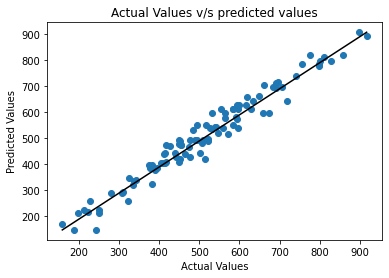

In [231]:
plt.scatter(Y_test,Y_pred)
plt.plot([Y_test.min(),Y_test.max()],[Y_pred.min(),Y_pred.max()],color='black')
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual Values v/s predicted values")


In [232]:
comp.corr()

,Actual Values,Decision Tree
Actual Values,1.000000,0.980483
Decision Tree,0.980483,1.000000


<Axes: >

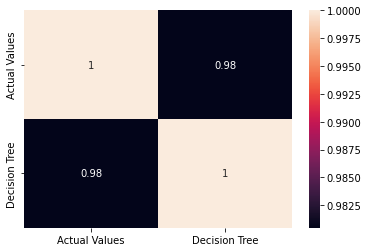

In [233]:
sns.heatmap(comp.corr(),annot=True)

<Axes: >

<Figure size 504x504 with 0 Axes>

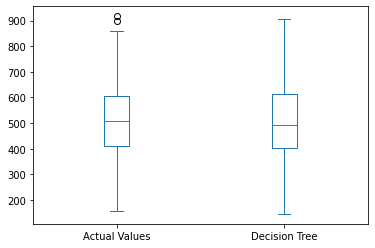

In [234]:
plt.figure(figsize=(7,7))
comp.plot.box()

Comparing with Linear Regression

In [235]:
Linreg=LinearRegression()

In [236]:
Linreg.fit(X_train,Y_train)

LinearRegression()

In [237]:
Linreg_pred=Linreg.predict(X_test)

In [251]:
Linreg.score(X_test,Y_test)

0.974469440281429

In [239]:
r2_score(Y_test,Linreg_pred)

0.974469440281429

In [240]:
mean_absolute_error(Y_test,Linreg_pred)

20.22987280504503

In [241]:
mean_squared_error(Y_test,Linreg_pred)

709.9145875262409

In [242]:
comp['Linreg']=Linreg_pred

In [243]:
comp

,Actual Values,Decision Tree,Linreg
0,443.113603,427.138369,441.768240
1,513.804382,417.354839,481.759644
2,740.935685,737.800824,725.375975
3,632.901914,639.538012,652.194499
4,474.832244,463.065614,455.111789
...,...,...,...
95,516.548601,550.055216,534.043774
96,599.278277,625.190122,603.652328
97,451.450784,417.354839,483.105234
98,520.470310,488.170809,501.361008


<Axes: >

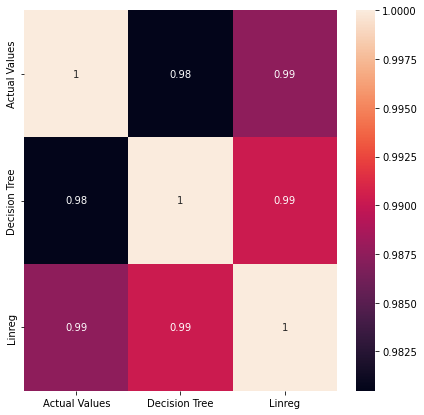

In [244]:
plt.figure(figsize=(7,7))
sns.heatmap(comp.corr(),annot=True)

Compare with SVR

In [252]:
suppvec=SVR()

In [253]:
suppvec.fit(X_train,Y_train)

c:\Users\arunk\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\utils\validation.py:1183: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


SVR()

In [254]:
suppvec_pred=suppvec.predict(X_test)

In [255]:
suppvec.score(X_test,Y_test)

0.539527105508166

In [256]:
r2_score(Y_test,suppvec_pred)

0.539527105508166